In [ ]:
'''!pip install -q --force-reinstall \
    torch==2.11.0 \
    torchvision \
    torchaudio \
    --index-url https://download.pytorch.org/whl/cu128'''

'!pip install -q --force-reinstall     torch==2.11.0     torchvision     torchaudio     --index-url https://download.pytorch.org/whl/cu128'

In [ ]:
pip install -q faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 48.3 MB/s eta 0:00:00


In [ ]:
pip install -q "dspy==3.3.1"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.0/43.0 kB 1.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.1/42.1 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 421.2/421.2 kB 25.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 290.2/290.2 kB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.3/51.3 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.1/28.1 MB 47.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.3/278.3 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 60.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 4.7 MB/s eta 0:00:00


# **Importing Libraries**

In [ ]:
# Check the clean PyTorch installation
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA: 12.8
CUDA available: True
GPU: Tesla T4


In [ ]:
# Test Transformers independently
import transformers

print("Transformers:", transformers.__version__)
print("Transformers imported successfully!")

Transformers: 5.16.1
Transformers imported successfully!


In [ ]:
# Reinstall compatible NumPy, SciPy, and scikit-learn versions
'''!pip install -q --force-reinstall --no-cache-dir \
    "numpy==2.1.3" \
    "scipy==1.15.3" \
    "scikit-learn==1.6.1"'''

'!pip install -q --force-reinstall --no-cache-dir     "numpy==2.1.3"     "scipy==1.15.3"     "scikit-learn==1.6.1"'

In [ ]:
# Test the scientific Python stack
import numpy as np
import scipy
import sklearn

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("scikit-learn:", sklearn.__version__)
print("Scientific Python stack: OK")

NumPy: 2.1.3
SciPy: 1.16.3
scikit-learn: 1.6.1
Scientific Python stack: OK


In [ ]:
# Test Sentence Transformers
from sentence_transformers import SentenceTransformer

print("Sentence Transformers imported successfully!")

Sentence Transformers imported successfully!


# **Mounting Google Drive and Defining Project Paths**


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/RAG_DSPy")
DATA_DIR = PROJECT_DIR / "data"
DOCUMENTS_DIR = DATA_DIR / "documents"
RESULTS_DIR = PROJECT_DIR / "results"

print("Project:", PROJECT_DIR)
print("Documents:", DOCUMENTS_DIR)
print("Evaluation file:", DATA_DIR / "evaluation_questions.csv")

print("\nDocuments found:")
for file in DOCUMENTS_DIR.iterdir():
    print("-", file.name)

Project: /content/drive/MyDrive/RAG_DSPy
Documents: /content/drive/MyDrive/RAG_DSPy/data/documents
Evaluation file: /content/drive/MyDrive/RAG_DSPy/data/evaluation_questions.csv

Documents found:
- rag_vector_databases.txt
- rag_indexes.txt
- rag_fundamentals.txt


# **Loading the documents**


In [ ]:
documents = []

for file in DOCUMENTS_DIR.glob("*.txt"):
    with open(file, "r", encoding="utf-8") as f:
        text = f.read()

    documents.append({
        "source": file.name,
        "text": text
    })

print(f"Number of documents loaded: {len(documents)}")

for doc in documents:
    print(f"- {doc['source']}: {len(doc['text'])} characters")

Number of documents loaded: 3
- rag_vector_databases.txt: 2752 characters
- rag_indexes.txt: 2414 characters
- rag_fundamentals.txt: 2960 characters


# **Creating the Same Document Chunks**

In [ ]:
import re

chunks = []

chunk_size = 5
chunk_overlap = 1

for doc in documents:
    sentences = re.split(
        r'(?<=[.!?])\s+',
        doc["text"].strip()
    )

    start = 0

    while start < len(sentences):
        end = min(start + chunk_size, len(sentences))

        chunk_text = " ".join(sentences[start:end])

        chunks.append({
            "source": doc["source"],
            "text": chunk_text
        })

        start += chunk_size - chunk_overlap

print(f"Total chunks created: {len(chunks)}")

Total chunks created: 29


# **Loading the Embedding Model**


In [ ]:
embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

print("Embedding model loaded successfully!")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded successfully!


# **Creating the FAISS vector index**


In [ ]:
import faiss

chunk_texts = [chunk["text"] for chunk in chunks]

chunk_embeddings = embedding_model.encode(
    chunk_texts,
    convert_to_numpy=True,
    normalize_embeddings=True
)

embedding_dim = chunk_embeddings.shape[1]

index = faiss.IndexFlatIP(embedding_dim)

index.add(
    chunk_embeddings.astype("float32")
)

print("FAISS index created successfully!")
print("Number of vectors:", index.ntotal)
print("Embedding dimensions:", embedding_dim)

FAISS index created successfully!
Number of vectors: 29
Embedding dimensions: 384


# **Loading Qwen2.5-3B-Instruct**

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

model_name = "Qwen/Qwen2.5-3B-Instruct"

# Load the tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load Qwen in FP16 for the T4 GPU
qwen_model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16
).to("cuda")

# Put the model in evaluation mode
qwen_model.eval()

print("Qwen loaded successfully!")
print("Model:", model_name)
print("Device:", qwen_model.device)
print("Dtype:", qwen_model.dtype)

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen loaded successfully!
Model: Qwen/Qwen2.5-3B-Instruct
Device: cuda:0
Dtype: torch.float16


# **Connecting Qwen to DSPy**

We create a custom dspy.BaseLM adapter because Qwen is running locally through Hugging Face Transformers rather than an API. It tells DSPy to send its generated prompts to the Qwen model and return the response in DSPy’s expected format.

In [ ]:
import dspy

print("DSPy version:", dspy.__version__)
print("DSPy imported successfully!")

DSPy version: 3.3.1
DSPy imported successfully!


In [ ]:
import json
import threading
from typing import Any

from dspy.core.types import LMOutput, LMResponse, LMTextPart, LMUsage


class TransformersLM(dspy.BaseLM):
    # Use DSPy's typed LM interface
    forward_contract = "typed_lm"

    def __init__(
        self,
        hf_model,
        tokenizer,
        model_name="Qwen/Qwen2.5-3B-Instruct",
        temperature=0.0,
        max_tokens=256,
        cache=True
    ):
        super().__init__(
            model=f"transformers/{model_name}",
            model_type="chat",
            temperature=temperature,
            max_tokens=max_tokens,
            cache=cache
        )

        self.hf_model = hf_model
        self.tokenizer = tokenizer
        self._lock = threading.Lock()
        self._memo = {}

    def forward(self, request: dspy.LMRequest) -> LMResponse:
        cfg = request.config

        messages = [
            {
                "role": message.role,
                "content": message.text or ""
            }
            for message in request.messages
        ]

        temperature = (
            cfg.temperature
            if cfg.temperature is not None
            else 0.0
        )

        max_tokens = (
            cfg.max_tokens
            or self.kwargs.get("max_tokens")
            or 256
        )

        n = cfg.n or 1
        stop = cfg.stop or []

        use_cache = (
            cfg.cache.enabled
            if cfg.cache and cfg.cache.enabled is not None
            else self.cache
        )

        rollout_id = cfg.cache.rollout_id if cfg.cache else None

        key = json.dumps(
            [
                messages,
                temperature,
                max_tokens,
                n,
                stop,
                rollout_id
            ],
            sort_keys=True,
            default=str
        )

        cache_hit = False

        if use_cache and key in self._memo:
            texts, n_in, n_out = self._memo[key]
            cache_hit = True

        else:
            with self._lock:
                texts, n_in, n_out = self._generate(
                    messages,
                    temperature,
                    max_tokens,
                    n
                )

            texts = [
                self._apply_stop(text, stop)
                for text in texts
            ]

            if use_cache:
                self._memo[key] = (
                    texts,
                    n_in,
                    n_out
                )

        return LMResponse(
            model=self.model,
            outputs=[
                LMOutput(
                    parts=[
                        LMTextPart(text=text)
                    ]
                )
                for text in texts
            ],
            usage=LMUsage(
                input_tokens=n_in,
                output_tokens=n_out
            ),
            cache_hit=cache_hit
        )

    def _generate(
        self,
        messages,
        temperature,
        max_tokens,
        n
    ):
        import torch

        # Convert messages into Qwen's chat format
        prompt = self.tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        # Tokenize the prompt
        inputs = self.tokenizer(
            prompt,
            return_tensors="pt"
        ).to(self.hf_model.device)

        n_in = int(
            inputs["input_ids"].shape[1]
        )

        pad_id = self.tokenizer.pad_token_id

        if pad_id is None:
            pad_id = self.tokenizer.eos_token_id

        # Configure generation
        gen_kwargs = {
            "max_new_tokens": int(max_tokens),
            "pad_token_id": pad_id
        }

        if temperature > 0:
            gen_kwargs.update({
                "do_sample": True,
                "temperature": float(temperature),
                "top_p": 0.9,
                "top_k": 50,
                "num_return_sequences": int(n)
            })
        else:
            gen_kwargs.update({
                "do_sample": False
            })

        # Generate the response
        with torch.inference_mode():
            output = self.hf_model.generate(
                **inputs,
                **gen_kwargs
            )

        # Keep only newly generated tokens
        new_tokens = output[
            :,
            n_in:
        ]

        # Convert tokens to text
        texts = [
            text.strip()
            for text in self.tokenizer.batch_decode(
                new_tokens,
                skip_special_tokens=True
            )
        ]

        n_out = int(
            (new_tokens != pad_id).sum().item()
        )

        # Replicate deterministic output if n > 1
        if not temperature > 0 and n > 1:
            texts = texts * int(n)

        return texts, n_in, n_out

    @staticmethod
    def _apply_stop(
        text: str,
        stop: list[str]
    ) -> str:

        for stop_string in stop:
            position = text.find(stop_string)

            if position != -1:
                text = text[:position]

        return text

# **Configuring DSPy with Qwen**

Register the locally loaded Qwen model as the language model used by DSPy.

In [ ]:
# Create the DSPy LM
lm = TransformersLM(
    hf_model=qwen_model,
    tokenizer=tokenizer,
    model_name="Qwen/Qwen2.5-3B-Instruct",
    temperature=0.0, #deterministic responses
    max_tokens=256
)

# Configure DSPy to use Qwen
dspy.configure(lm=lm)

print("Qwen is now configured as the DSPy language model!")

Qwen is now configured as the DSPy language model!


# **Testing DSPy + Qwen**

Verify that DSPy can send a prompt to the locally loaded Qwen model and receive a structured answer.

In [ ]:
# Create a simple DSPy predictor
qa = dspy.Predict("question -> answer")

# Ask Qwen a simple question through DSPy
result = qa(
    question="In one sentence, what is Retrieval-Augmented Generation?"
)

print("Answer:")
print(result.answer)

Answer:
Retrieval-Augmented Generation is a method that combines retrieval of relevant information from a large corpus with natural language generation to improve the quality and diversity of generated text.


# **Defining the FAISS Retriever**

Create the retrieval function used by the DSPy RAG module. It searches the existing FAISS index and returns the most relevant document chunks.

In [ ]:
def retrieve_context(query, k=3):
    # Create an embedding for the question
    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    # Search the FAISS index
    scores, indices = index.search(
        query_embedding,
        k
    )

    # Store retrieved chunks
    retrieved_chunks = []

    for score, idx in zip(scores[0], indices[0]):
        if idx != -1:
            retrieved_chunks.append({
                **chunks[idx],
                "score": float(score)
            })

    return retrieved_chunks

print("FAISS retrieval function created successfully!")

FAISS retrieval function created successfully!


# **Defining the DSPy Signature**

A DSPy Signature defines what information the language model receives and what it should produce.

For our RAG system:
- `context` is the information retrieved by FAISS.
- `question` is the user's question.
- `answer` is the response generated by Qwen.

The signature describes the task without manually writing the complete prompt.

In [ ]:
class RAGAnswer(dspy.Signature):
    #Answer the question using only the retrieved context.

    context: str = dspy.InputField(
        desc="Relevant passages retrieved from the knowledge base"
    )

    question: str = dspy.InputField(
        desc="User question"
    )

    answer: str = dspy.OutputField(
        desc="Concise answer grounded in the provided context"
    )

print("RAG signature created successfully!")

RAG signature created successfully!


# **Creating the DSPy RAG Module**

Create the RAG program.

In [ ]:
class RAG(dspy.Module):

    def __init__(self, k=3):
        super().__init__()

        self.k = k
        self.respond = dspy.ChainOfThought(RAGAnswer)

    def forward(self, question):

        # Retrieve relevant chunks
        retrieved = retrieve_context(
            question,
            k=self.k
        )

        # Combine retrieved chunks into context
        context = "\n\n".join(
            chunk["text"]
            for chunk in retrieved
        )

        # Generate an answer using DSPy and Qwen
        prediction = self.respond(
            context=context,
            question=question
        )

        # Return answer and retrieval information
        return dspy.Prediction(
            answer=prediction.answer,
            context=context,
            retrieved_chunks=retrieved,
            reasoning=getattr(
                prediction,
                "reasoning",
                None
            )
        )

print("DSPy RAG module created successfully!")

DSPy RAG module created successfully!


# **Testing the complete DSPy + RAG pipeline**

In [ ]:
# Create the RAG program
rag = RAG(k=3)

# Test with one question
question = "What is Retrieval-Augmented Generation?"

result = rag(question=question)

print("Question:")
print(question)

print("\nAnswer:")
print(result.answer)

print("\nRetrieved Sources:")
for chunk in result.retrieved_chunks:
    print(
        f"- {chunk['source']} "
        f"(score: {chunk['score']:.4f})"
    )

print("\nReasoning:")
print(result.reasoning)

Question:
What is Retrieval-Augmented Generation?

Answer:
Retrieval-Augmented Generation (RAG) is an architecture that combines information retrieval with a large language model (LLM).

[[## completed ##]]

Retrieved Sources:
- rag_fundamentals.txt (score: 0.6240)
- rag_indexes.txt (score: 0.6217)
- rag_fundamentals.txt (score: 0.6175)

Reasoning:
The question asks about the definition of Retrieval-Augmented Generation (RAG). The provided context directly states that "Retrieval-Augmented Generation (RAG) is an architecture that combines information retrieval with a large language model (LLM)."


# **Loading Evaluation Set**

In [ ]:
import pandas as pd
import random

# Load evaluation questions
df = pd.read_csv(
    "/content/drive/MyDrive/RAG_DSPy/data/evaluation_questions.csv"
)

print("Number of questions:", len(df))
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst question:")
print(df.iloc[0]["question"])

Number of questions: 25

Columns:
['question_id', 'question', 'reference_answer']

First question:
What is Retrieval-Augmented Generation (RAG)?


# **Creating Train and Test Sets**

Split the 25 evaluation questions into a training set for DSPy optimization and a held-out test set for final evaluation.

In [ ]:
# Create DSPy examples
examples = [
    dspy.Example(
        question=row["question"],
        answer=row["reference_answer"]
    ).with_inputs("question")
    for _, row in df.iterrows()
]

# Use a fixed seed for reproducibility
random.Random(42).shuffle(examples)

# Split the dataset
trainset = examples[:15]
testset = examples[15:]

print("Training questions:", len(trainset))
print("Test questions:", len(testset))

Training questions: 15
Test questions: 10


# **Evaluation Mtric used by DSPy Optimizer**

This cell defines the evaluation metric for the RAG system by combining 50% semantic similarity between the generated and reference answers with 50% token-level F1, giving an overall score from 0 to 1. During DSPy optimization, answers scoring ≥ 0.5 are treated as successful examples for the optimizer.

In [ ]:
import re
import numpy as np

def tokenize(text):
    # Convert text into lowercase tokens
    return re.findall(r"\w+", str(text).lower())


def token_f1(predicted, reference):
    # Tokenize both answers
    pred_tokens = tokenize(predicted)
    ref_tokens = tokenize(reference)

    if not pred_tokens or not ref_tokens:
        return 0.0

    # Count matching tokens
    common = sum(
        min(pred_tokens.count(token), ref_tokens.count(token))
        for token in set(pred_tokens)
    )

    if common == 0:
        return 0.0

    precision = common / len(pred_tokens)
    recall = common / len(ref_tokens)

    return (
        2 * precision * recall /
        (precision + recall)
    )


def answer_metric(example, prediction, trace=None):
    # Get the generated and reference answers
    predicted_answer = prediction.answer or ""
    reference_answer = example.answer or ""

    # Generate normalized embeddings
    embeddings = embedding_model.encode(
        [predicted_answer, reference_answer],
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    # Calculate semantic similarity
    semantic_score = max(
        0.0,
        float(np.dot(embeddings[0], embeddings[1]))
    )

    # Calculate token F1
    f1_score = token_f1(
        predicted_answer,
        reference_answer
    )

    # Combine the scores
    score = (
        0.5 * semantic_score +
        0.5 * f1_score
    )

    # Return boolean during DSPy optimization
    if trace is not None:
        return score >= 0.5

    return score


print("Evaluation metric restored successfully!")

Evaluation metric restored successfully!


# **Optimizing the DSPy RAG Program**

Use DSPy's BootstrapFewShot optimizer to improve the RAG program using the 15-question training set. The 10-question test set remains held out for final comparison.

In [ ]:
# Create the DSPy optimizer
optimizer = dspy.BootstrapFewShot(
    metric=answer_metric,
    max_bootstrapped_demos=2,
    max_labeled_demos=0,
    max_rounds=1
)

print("Starting DSPy optimization...")

# Optimize the RAG program
optimized_rag = optimizer.compile(
    RAG(k=3),
    trainset=trainset
)

print("DSPy optimization completed!")

Starting DSPy optimization...


 40%|████      | 6/15 [00:29<00:44,  4.97s/it]

Bootstrapped 2 full traces after 6 examples for up to 1 rounds, amounting to 6 attempts.
DSPy optimization completed!


# **Inspecting the Optimized DSPy Program**

Inspect the optimized predictor to verify that DSPy successfully added the bootstrapped demonstrations.

In [ ]:
# Inspect the optimized program
print(optimized_rag)

# Show the predictors available in the optimized program
print("\nOptimized predictors:")

for name, predictor in optimized_rag.named_predictors():
    print("\nPredictor:", name)
    print(predictor)

respond.predict = Predict(StringSignature(context, question -> reasoning, answer
    instructions='Given the fields `context`, `question`, produce the fields `answer`.'
    context = Field(annotation=str required=True json_schema_extra={'desc': 'Relevant passages retrieved from the knowledge base', '__dspy_field_type': 'input', 'prefix': 'Context:'})
    question = Field(annotation=str required=True json_schema_extra={'desc': 'User question', '__dspy_field_type': 'input', 'prefix': 'Question:'})
    reasoning = Field(annotation=str required=True json_schema_extra={'desc': '${reasoning}', '__dspy_field_type': 'output', 'prefix': 'Reasoning:'})
    answer = Field(annotation=str required=True json_schema_extra={'desc': 'Concise answer grounded in the provided context', '__dspy_field_type': 'output', 'prefix': 'Answer:'})
))

Optimized predictors:

Predictor: respond.predict
Predict(StringSignature(context, question -> reasoning, answer
    instructions='Given the fields `context`, `questi

In [ ]:
predictor = optimized_rag.respond.predict

print("Optimized demonstrations:")
print("=" * 60)

for i, demo in enumerate(predictor.demos, 1):
    print(f"\nDemo {i}:")
    print(demo)

Optimized demonstrations:

Demo 1:
Example({'augmented': True, 'context': 'Embeddings\n\nAn embedding is a numerical representation of text or another piece of data. Text with similar meaning can have similar vector representations. Embeddings allow a retrieval system to perform semantic similarity search. A user question can be converted into an embedding and compared with embeddings of document chunks. 6.\n\n4. Embeddings\n\nEmbeddings are numerical representations of content. They can be used for vector similarity search. The document chunks and user queries are represented in the same embedding space so that the system can search for semantically related information. 5.\n\nVector embeddings\n\nAn embedding converts text into a numerical vector. The vector represents semantic characteristics of the text. For example, two pieces of text with related meanings can have vectors that are close to each other in vector space. This makes embeddings useful for semantic search. 3.', 'question

### **Evaluation Metrics**



In [ ]:
from dspy.evaluate import SemanticF1
import pandas as pd
import time

# DSPy's official SemanticF1 metric
semantic_f1 = SemanticF1(decompositional=True)

print("SemanticF1 evaluator ready!")

SemanticF1 evaluator ready!


In [ ]:
def evaluate_semantic_f1(rag_system, testset):

    results = []

    for i, example in enumerate(testset, start=1):

        start_time = time.time()

        # Run RAG
        prediction = rag_system(
            question=example.question
        )

        latency = time.time() - start_time

        # SemanticF1 expects:
        # example.question
        # example.response
        eval_example = dspy.Example(
            question=example.question,
            response=example.answer
        ).with_inputs("question")

        # SemanticF1 expects:
        # pred.response
        eval_prediction = dspy.Prediction(
            response=prediction.answer
        )

        # Run SemanticF1
        metric_result = semantic_f1(
            eval_example,
            eval_prediction
        )

        # Extract the actual numeric score
        score = float(metric_result.score)

        results.append({
            "question": example.question,
            "reference_answer": example.answer,
            "generated_answer": prediction.answer,
            "semantic_f1": score,
            "latency_seconds": latency
        })

        print(
            f"Question {i}/{len(testset)} | "
            f"SemanticF1: {score:.3f}"
        )

    return pd.DataFrame(results)

# **Evaluate BEFORE optimization**

In [ ]:
before_df = evaluate_semantic_f1(
    RAG(k=3),
    testset
)

before_score = before_df["semantic_f1"].mean()

print("\n" + "=" * 50)
print("BEFORE DSPy OPTIMIZATION")
print("=" * 50)
print(f"Average SemanticF1: {before_score:.4f}")

Question 1/10 | SemanticF1: 1.000
Question 2/10 | SemanticF1: 1.000
Question 3/10 | SemanticF1: 0.500
Question 4/10 | SemanticF1: 1.000
Question 5/10 | SemanticF1: 1.000
Question 6/10 | SemanticF1: 0.857
Question 7/10 | SemanticF1: 0.789
Question 8/10 | SemanticF1: 1.000
Question 9/10 | SemanticF1: 0.889
Question 10/10 | SemanticF1: 0.600

BEFORE DSPy OPTIMIZATION
Average SemanticF1: 0.8636


In [ ]:
after_df = evaluate_semantic_f1(
    optimized_rag,
    testset
)

after_score = after_df["semantic_f1"].mean()

print("\n" + "=" * 50)
print("AFTER DSPy OPTIMIZATION")
print("=" * 50)
print(f"Average SemanticF1: {after_score:.4f}")

Question 1/10 | SemanticF1: 0.706
Question 2/10 | SemanticF1: 1.000
Question 3/10 | SemanticF1: 0.774
Question 4/10 | SemanticF1: 0.667
Question 5/10 | SemanticF1: 1.000
Question 6/10 | SemanticF1: 1.000
Question 7/10 | SemanticF1: 1.000
Question 8/10 | SemanticF1: 0.500
Question 9/10 | SemanticF1: 0.857
Question 10/10 | SemanticF1: 0.808

AFTER DSPy OPTIMIZATION
Average SemanticF1: 0.8312


# Gradio UI


In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr


def rag_chat(question):
    if not question or not question.strip():
        return "Please enter a question."

    try:
        prediction = optimized_rag(
            question=question.strip()
        )

        return prediction.answer

    except Exception as e:
        return f"Error: {str(e)}"

In [ ]:
with gr.Blocks(title="RAG Knowledge Assistant") as demo:

    gr.Markdown(
        """
        # 📚 RAG Knowledge Assistant

        Ask a question about **Retrieval-Augmented Generation (RAG)**.

        The assistant retrieves relevant information from the knowledge base
        and uses the language model to generate an answer.
        """
    )

    chatbot = gr.Chatbot(
        label="RAG Assistant",
        height=500
    )

    question = gr.Textbox(
        label="Your Question",
        placeholder="Ask something about RAG...",
        lines=2
    )

    with gr.Row():
        submit = gr.Button("Ask", variant="primary")
        clear = gr.Button("Clear")

    def respond(message, history):
        answer = rag_chat(message)

        history = history or []

        history.append({
            "role": "user",
            "content": message
        })

        history.append({
            "role": "assistant",
            "content": answer
        })

        return "", history

    submit.click(
        respond,
        inputs=[question, chatbot],
        outputs=[question, chatbot]
    )

    question.submit(
        respond,
        inputs=[question, chatbot],
        outputs=[question, chatbot]
    )

    clear.click(
        lambda: ([], ""),
        outputs=[chatbot, question]
    )


demo.launch(share=True)

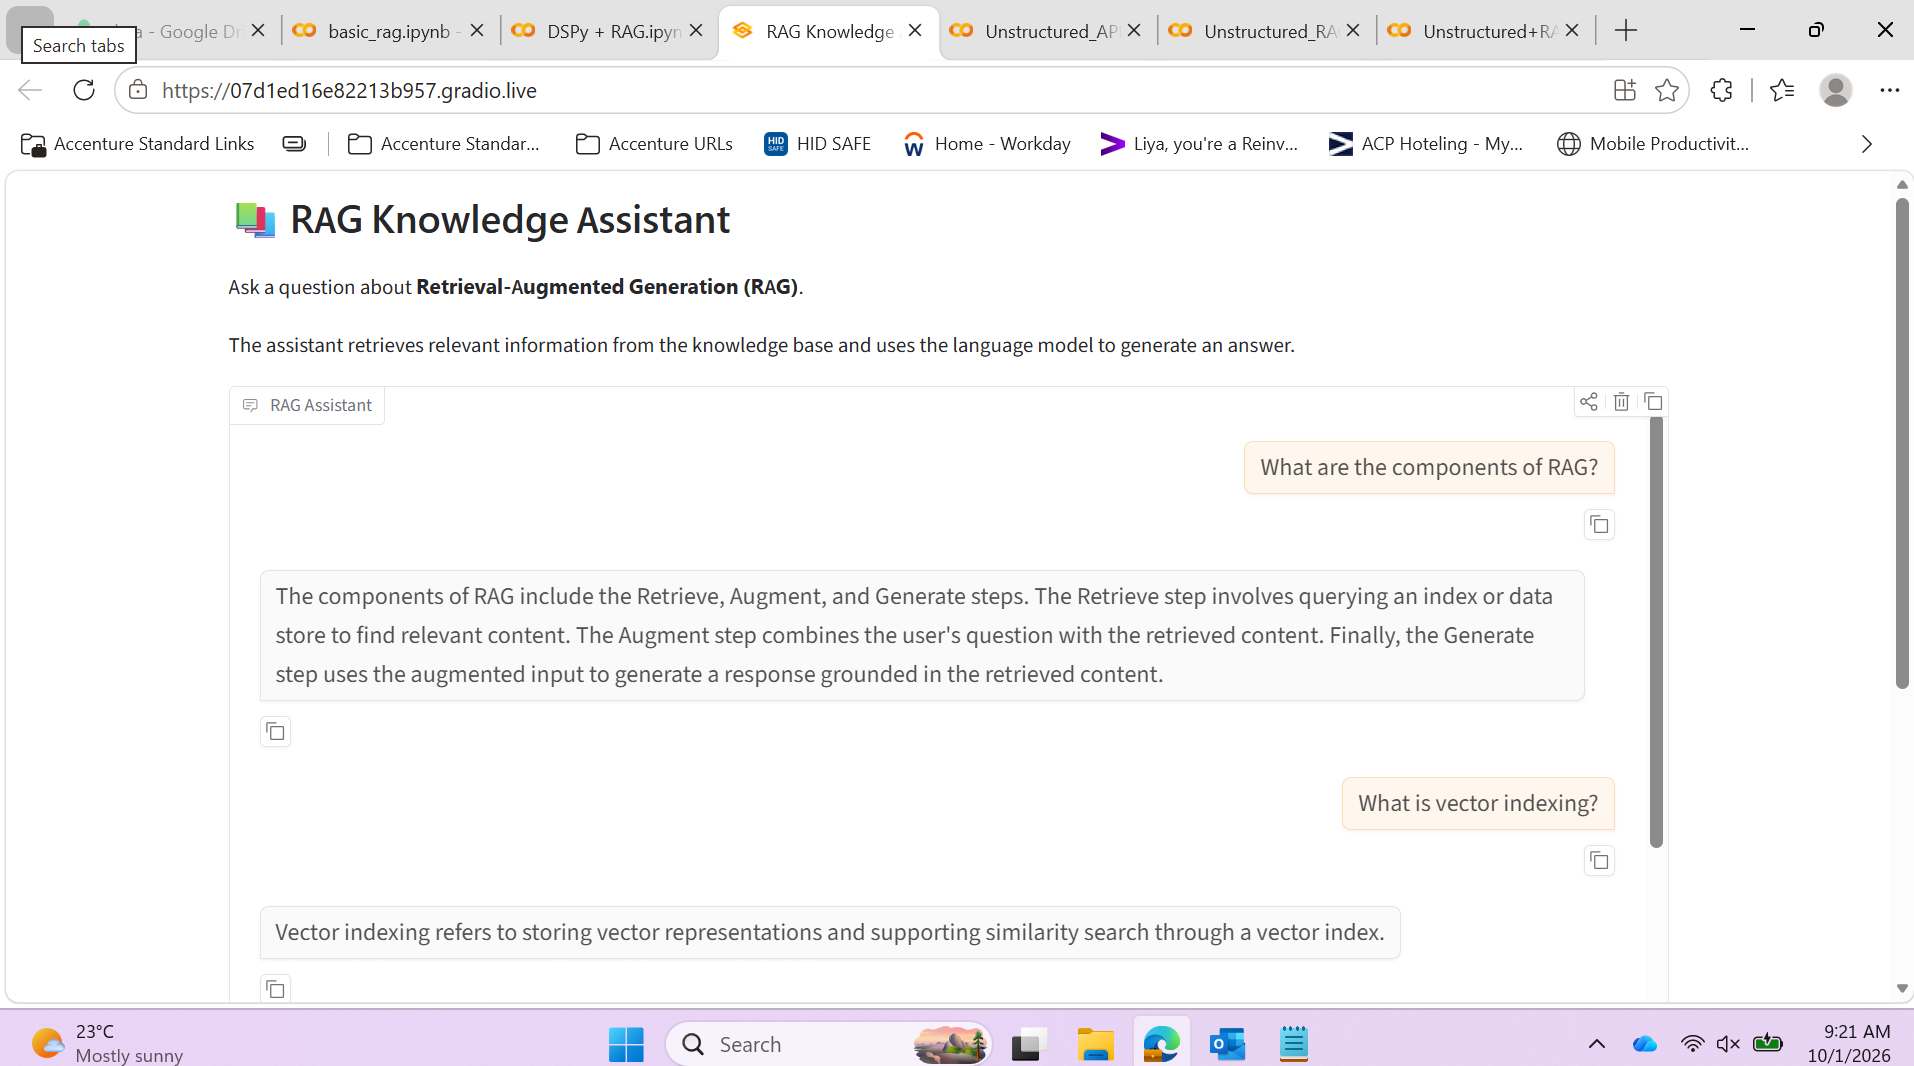

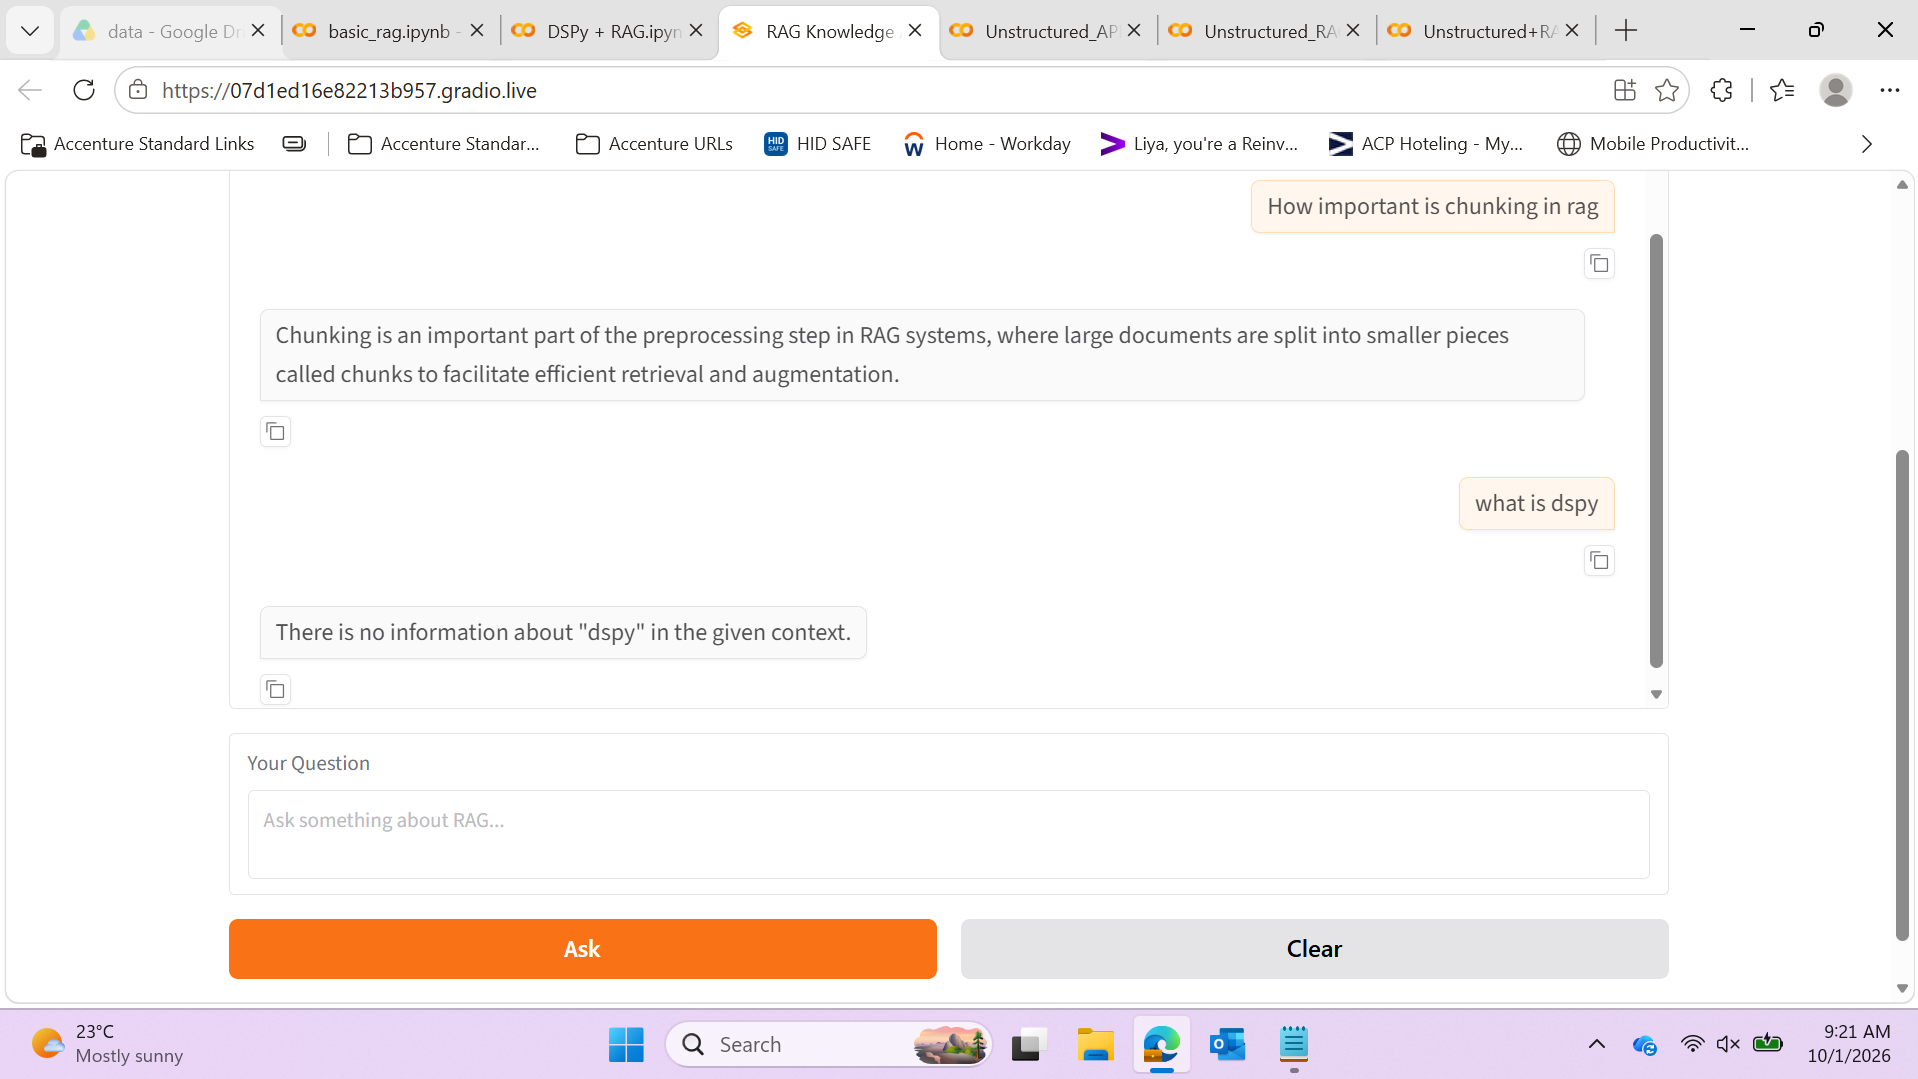